# Comparer cinq domaines de recommandation

Les interactions sont synthétiques par défaut. Le notebook lit les imports locaux s’ils sont présents.

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd

from reco_platform.config import load_configs
from reco_platform.data import read_dataset

configs = load_configs()
datasets = {slug: read_dataset(config) for slug, config in configs.items()}
stats = []
for slug, data in datasets.items():
    events = data.interactions
    n_users, n_items = events["user_id"].nunique(), len(data.items)
    positives = events[events["feedback"].ge(configs[slug].positive)]
    stats.append({"Domaine": configs[slug].label, "Catalogue": n_items,
                  "Profils": n_users, "Interactions": len(events),
                  "Sparsité": 1 - len(events) / max(1, n_users * n_items),
                  "Taux positif": len(positives) / max(1, len(events)),
                  "Démo": data.demo, "Horodaté": data.temporal})
pd.DataFrame(stats).round(3)

Domaine,Catalogue,Profils,Interactions,Sparsité,Taux positif,Démo,Horodaté
Livres,20,150,1134,0.622,0.693,True,True
Jeux,20,150,1096,0.635,0.681,True,True
Films,20,150,1113,0.629,0.733,True,True
Musique,18,150,1163,0.569,0.696,True,True
Recettes,20,150,1139,0.620,0.681,True,True


## Fréquence d’exposition par élément

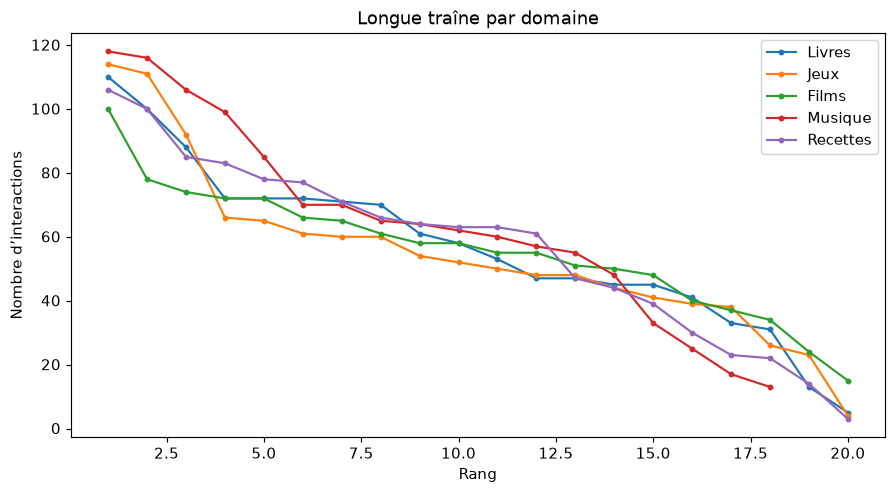

In [2]:
fig, ax = plt.subplots(figsize=(10, 5))
for slug, data in datasets.items():
    counts = sorted(Counter(data.interactions["item_id"]).values(), reverse=True)
    ax.plot(range(1, len(counts) + 1), counts, marker=".", label=configs[slug].label)
ax.set(xlabel="Rang", ylabel="Nombre d’interactions", title="Longue traîne par domaine")
ax.legend()
plt.show()

## Distribution du feedback

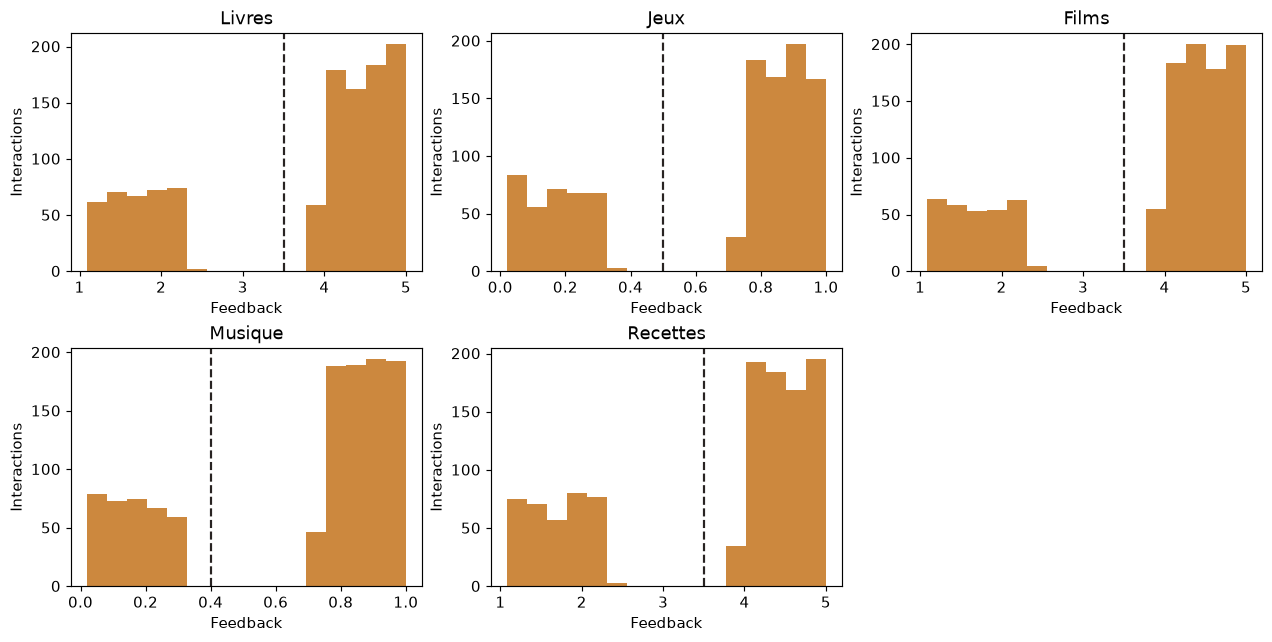

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6), layout="constrained")
for (slug, data), ax in zip(datasets.items(), axes.flat):
    ax.hist(data.interactions["feedback"], bins=16, color="#cc883e")
    ax.axvline(configs[slug].positive, color="#282322", linestyle="--")
    ax.set(title=configs[slug].label, xlabel="Feedback", ylabel="Interactions")
for ax in list(axes.flat)[len(datasets):]:
    ax.set_visible(False)
plt.show()

Les histogrammes utilisent les échelles d’origine des signaux. Les seuils positifs sont propres aux domaines.